# Regresión logística balanceada

**Inteligencia Artificial Aplicada (1INF62) — Pontificia Universidad Católica del Perú, 2026-2**

**Integrantes:** Aguilera, Jair · Araujo, Luis · Condori, Nilton · Vilcayauri, Pedro

---

### Abstract

Este notebook entrena la regresión logística con balanceo de clases por pesos (`class_weight="balanced"`), el modelo con mejor desempeño en Almeida et al. (2026). El balanceo da a cada caso de bajo peso un peso inverso a su frecuencia, sin crear datos nuevos. Usa las 9 features del EDA, casos completos y la partición temporal. La fuerza de la regularización (`C`) y su tipo (L1 o L2) se eligen por AUC-PR en validación, como en el tutorial de clasificación del curso; el test (2024–2025) se usa una sola vez. Se compara con el baseline (regresión logística simple).

**Resultado principal:** se eligió L2 con C = 0.0001. En el test (2024–2025) la regresión balanceada discrimina igual que el baseline (AUC-ROC 0.908 en ambos; AUC-PR 0.677 en ambos). Con el umbral 0.5, el balanceo sube el recall de 0.47 a 0.81 a costa de bajar la precisión de 0.82 a 0.31: cambia el punto de operación, no la capacidad de discriminar.

### Estructura del notebook

1. Configuración del entorno
2. Datos y partición temporal
3. Ajuste de hiperparámetros (C × tipo de penalización)
4. Modelo final y evaluación en test
5. Interpretación
6. Limitaciones

## 1. Configuración del entorno

El notebook funciona en Google Colab y en local, igual que el EDA. En Colab clona o actualiza el repositorio; en local asume que se ejecuta desde `proyecto/notebooks/`. Todo el preprocesamiento se importa de `src/preprocessing.py`, para que los cinco modelos usen exactamente los mismos datos y la misma partición.

In [1]:
import sys, gc, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/jasnai10/AI_Project.git"

if IN_COLAB:
    if not Path("/content/AI_Project").exists():
        !git clone -q {REPO_URL} /content/AI_Project
    else:
        !git -C /content/AI_Project pull -q
    ROOT = Path("/content/AI_Project/proyecto")
else:
    ROOT = Path.cwd().parent

sys.path.insert(0, str(ROOT))
from src.preprocessing import (cargar_cnv, limpiar, seleccionar_features, columnas_features,
                               dividir_temporal, construir_preprocesador, SEMILLA)

pd.set_option("display.float_format", "{:,.4f}".format)
print("Entorno:", "Colab" if IN_COLAB else "local", "| ROOT:", ROOT)

Entorno: Colab | ROOT: /content/AI_Project/proyecto


## 2. Datos y partición temporal

Se carga el CNV original desde `data/raw/dataset.zip` y se aplican `limpiar()` y `seleccionar_features()` (9 features, casos completos). La partición es la **temporal** definida en el EDA:

| Conjunto | Años | Uso |
|---|---|---|
| Train | 2015–2023 (80% al azar, estratificado) | Ajustar el modelo y el preprocesador |
| Validación | 2015–2023 (20% restante) | Elegir C y el tipo de penalización |
| Test | 2024–2025 | Evaluación final, una sola vez |

El test simula el uso real: entrenar con el pasado y predecir el futuro. Su prevalencia (6.81%) es mayor que la de train (6.32%), así que la precisión y el F1 en test cambian de nivel aunque el modelo sea el mismo. Por eso los modelos se comparan sobre todo con métricas que no dependen de la prevalencia ni del umbral. 2025 llega hasta el 30/11/2025, sin diciembre.

In [2]:
df_raw, _ = cargar_cnv(ruta_zip=ROOT / "data" / "raw" / "dataset.zip")
df = limpiar(df_raw)
del df_raw; gc.collect()

X, y = seleccionar_features(df, target="bajo_peso")
X_tr, X_val, X_te, y_tr, y_val, y_te = dividir_temporal(X, y, df["anio"])
anio = df["anio"]
resumen = pd.DataFrame({
    "años": [f"{anio[X_tr.index].min()}-{anio[X_tr.index].max()}",
             f"{anio[X_val.index].min()}-{anio[X_val.index].max()}",
             f"{anio[X_te.index].min()}-{anio[X_te.index].max()}"],
    "registros": [len(y_tr), len(y_val), len(y_te)],
    "casos_bajo_peso": [int(y_tr.sum()), int(y_val.sum()), int(y_te.sum())],
    "prevalencia_%": [y_tr.mean() * 100, y_val.mean() * 100, y_te.mean() * 100]},
    index=["train", "validación", "test"])
del X, y, df, anio; gc.collect()
cat_cols, num_cols = columnas_features()
resumen.round(2)

Cargado CNV_MINSA_CORTE_30112025.csv: 4,874,510 filas, 22 columnas | filas reparadas: 388 | descartadas: 0
limpiar(): 4,874,510 → 4,871,486 filas (eliminadas 3,024 sin peso válido) | prevalencia de bajo peso: 6.38%
target=bajo_peso | 9 features | casos completos: 4,764,960 de 4,871,486 (97.81%)


,años,registros,casos_bajo_peso,prevalencia_%
train,2015-2023,3237829,204500,6.3200
validación,2015-2023,809458,51125,6.3200
test,2024-2025,717673,48907,6.8100


## 3. Ajuste de hiperparámetros

La regresión logística elige los coeficientes que minimizan la **pérdida logística (ponderada por clase) + penalización / C**. Se ajustan los dos hiperparámetros que definen esa penalización, es decir, que cambian el modelo:

| Hiperparámetro | Qué controla | Valores |
|---|---|---|
| `C` | Inverso de la fuerza de la regularización. Un C pequeño castiga más los coeficientes grandes (modelo más simple, riesgo de subajuste); uno grande deja que el modelo se ajuste más a los datos (riesgo de sobreajuste). | 0.00001, 0.0001, 0.001, 0.01, 0.1, 1 |
| `l1_ratio` | Tipo de penalización. `0` = L2 (Ridge): encoge todos los coeficientes sin llevarlos a cero. `1` = L1 (Lasso): puede dejar coeficientes en exactamente cero, es decir, descarta categorías poco útiles. | 0 (L2), 1 (L1) |

`class_weight="balanced"` queda fijo porque define el modelo de Almeida et al. (2026). En scikit-learn ≥ 1.8 el tipo de penalización se indica con `l1_ratio` (el parámetro `penalty` está deprecado), pero en versiones anteriores, como la que trae Colab, `l1_ratio` se ignora salvo con elastic-net y hay que usar `penalty`. La función `regresion_logistica` elige la forma correcta según la versión instalada, para que L1 sea realmente L1 en cualquier entorno.

**Solver.** El solver es el algoritmo que busca el mínimo; no cambia el modelo, solo cómo se encuentra. Se usa `saga` en todas las combinaciones porque es el único que admite L1 y L2 minimizando exactamente la misma fórmula (`lbfgs` solo admite L2, porque L1 no tiene derivada en cero; `liblinear` además penaliza el intercepto). Así, lo único que cambia entre combinaciones son los hiperparámetros del modelo. La tabla incluye el número de iteraciones para comprobar que cada ajuste convergió (menos de `max_iter=1000`) y cuántos coeficientes quedaron en cero.

**Criterio de selección: AUC-PR en validación.** El preprocesador y los modelos se ajustan **solo con train**. Todo lo que quede a menos de 0.001 del mejor AUC-PR se considera un empate (diferencias menores son ruido de la partición); entre empates se prefiere L2 (el estándar) y luego el C menor, que da el modelo más regularizado. El modelo final es el elegido, ya entrenado con train: no se reentrena con validación, así que el modelo que se evalúa en test es exactamente el que se eligió.

> **Tiempo:** son 12 ajustes (6 valores de C × 2 penalizaciones). En Colab cada ajuste tardó unos 30 a 50 segundos, salvo L1 con C = 1 (unos 3 minutos); la grilla completa, unos 12 minutos. No se incluye C=10: con C ≥ 0.01 el modelo ya no cambia y es el ajuste más lento.

### Métricas

- **AUC-ROC y AUC-PR:** no dependen del umbral. Son las métricas principales para comparar modelos. El AUC-PR de un clasificador al azar es igual a la prevalencia (0.0681 en test), no a 0.5.
- **Precisión, recall y F1 con umbral 0.5:** el umbral **no se calibra**, igual que en Almeida et al. (2026), Khan et al. (2022) y Ranjbar et al. (2023), que usaron el valor por defecto de sus librerías. Así las cifras son comparables con las de los papers.
- **Accuracy:** solo como referencia. Con 6-7% de prevalencia, predecir siempre "no bajo peso" ya da cerca de 93%.

scikit-learn 1.6.1


,penalizacion,C,auc_pr_train,auc_pr_val,auc_roc_val,precision_val,recall_val,f1_val,accuracy_val,coef_en_cero,iteraciones,seg
0,L2,1e-05,0.6623,0.6614,0.9003,0.3326,0.7714,0.4648,0.8878,0,15,41.2301
1,L2,0.0001,0.6667,0.6655,0.9040,0.3171,0.7863,0.4519,0.8795,0,16,44.0902
2,L2,0.001,0.6653,0.6639,0.9051,0.3114,0.7904,0.4467,0.8764,0,17,45.1043
3,L2,0.01,0.6646,0.6633,0.9052,0.3094,0.7914,0.4448,0.8752,0,17,45.4096
4,L2,0.1,0.6646,0.6632,0.9052,0.3094,0.7915,0.4449,0.8753,0,17,44.3043
5,L2,1,0.6646,0.6632,0.9052,0.3094,0.7915,0.4449,0.8753,0,17,45.8954
6,L1,1e-05,0.5925,0.5923,0.8867,0.3198,0.7658,0.4512,0.8823,52,11,29.7195
7,L1,0.0001,0.6622,0.6612,0.9001,0.3376,0.7707,0.4695,0.8900,43,15,42.4962
8,L1,0.001,0.6653,0.6641,0.9047,0.3137,0.7888,0.4489,0.8777,14,17,46.9248
9,L1,0.01,0.6647,0.6634,0.9052,0.3105,0.7908,0.4459,0.8759,6,17,49.6010


Todos los ajustes convergieron: True | columnas del modelo: 53


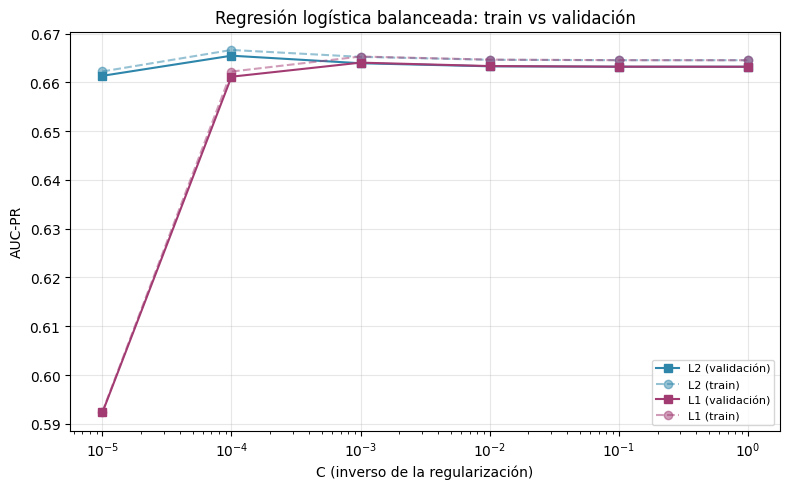

Combinaciones empatadas con el mejor AUC-PR: 1 de 12
Elegido: penalización L2, C=0.0001


In [3]:
UMBRAL = 0.5

def evaluar(y_true, p, umbral=UMBRAL):
    pred = (p >= umbral).astype(int)
    return {"auc_roc": roc_auc_score(y_true, p),
            "auc_pr": average_precision_score(y_true, p),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "accuracy": accuracy_score(y_true, pred)}

import sklearn
VERSION_SK = tuple(int(x) for x in sklearn.__version__.split(".")[:2])

def regresion_logistica(C, penalizacion, **kwargs):
    # Regresión logística con penalización L1 o L2 según la versión de scikit-learn.
    # En >= 1.8 el tipo se indica con l1_ratio (penalty está deprecado); en versiones anteriores
    # (como la que trae Colab) se indica con penalty, porque ahí l1_ratio se ignora salvo con elastic-net.
    if VERSION_SK >= (1, 8):
        return LogisticRegression(C=C, l1_ratio={"L2": 0, "L1": 1}[penalizacion], **kwargs)
    return LogisticRegression(C=C, penalty=penalizacion.lower(), **kwargs)

print("scikit-learn", sklearn.__version__)

prep = construir_preprocesador().fit(X_tr)                      # fit SOLO con train
Xtr_t, Xval_t = prep.transform(X_tr), prep.transform(X_val)

filas, modelos = [], {}
for penalizacion in ["L2", "L1"]:
    for C in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]:
        t0 = time.time()
        m = regresion_logistica(C, penalizacion, solver="saga", class_weight="balanced",
                                max_iter=1000, random_state=SEMILLA).fit(Xtr_t, y_tr)
        p_tr, p_val = m.predict_proba(Xtr_t)[:, 1], m.predict_proba(Xval_t)[:, 1]
        v = evaluar(y_val, p_val)
        modelos[(penalizacion, C)] = m
        filas.append({"penalizacion": penalizacion, "C": C,
                      "auc_pr_train": average_precision_score(y_tr, p_tr), "auc_pr_val": v["auc_pr"],
                      "auc_roc_val": v["auc_roc"],
                      "precision_val": v["precision"], "recall_val": v["recall"], "f1_val": v["f1"],
                      "accuracy_val": v["accuracy"],
                      "coef_en_cero": int((m.coef_ == 0).sum()), "iteraciones": int(m.n_iter_[0]),
                      "seg": time.time() - t0})
res = pd.DataFrame(filas)
display(res.round(4).assign(C=res["C"].map("{:g}".format)))   # C en notación legible (1e-05, 0.0001, ...)
print("Todos los ajustes convergieron:", bool((res["iteraciones"] < 1000).all()),
      f"| columnas del modelo: {Xtr_t.shape[1]}")

fig, ax = plt.subplots(figsize=(8, 5))
for pen, col in zip(["L2", "L1"], ["#2E86AB", "#A23B72"]):
    d = res[res.penalizacion == pen]
    ax.plot(d.C, d.auc_pr_val, "s-", color=col, label=f"{pen} (validación)")
    ax.plot(d.C, d.auc_pr_train, "o--", color=col, alpha=.5, label=f"{pen} (train)")
ax.set_xscale("log"); ax.set_xlabel("C (inverso de la regularización)"); ax.set_ylabel("AUC-PR")
ax.set_title("Regresión logística balanceada: train vs validación")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

empates = res[res["auc_pr_val"] >= res["auc_pr_val"].max() - 0.001].copy()
empates["p"] = empates["penalizacion"].map({"L2": 0, "L1": 1})
mejor = empates.sort_values(["p", "C"]).iloc[0]
print(f"Combinaciones empatadas con el mejor AUC-PR: {len(empates)} de {len(res)}")
print(f"Elegido: penalización {mejor['penalizacion']}, C={mejor['C']}")
del Xtr_t, Xval_t; _ = gc.collect()

## 4. Modelo final y evaluación en test

El modelo final es el elegido en la sección 3 (ya entrenado con train), unido a su preprocesador en un `Pipeline`, y se evalúa **una sola vez** en el test (2024–2025). Como referencia se incluye el baseline (regresión logística simple, `C=1`, sin balanceo), entrenado con los mismos datos.

In [4]:
final = Pipeline([("prep", prep), ("clf", modelos[(mejor["penalizacion"], float(mejor["C"]))])])   # pasos ya ajustados con train
baseline = Pipeline([("prep", construir_preprocesador()),
                     ("clf", LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=SEMILLA))]).fit(X_tr, y_tr)

probas_te = {"RL balanceada": final.predict_proba(X_te)[:, 1],
             "RL simple (baseline)": baseline.predict_proba(X_te)[:, 1]}
metricas = pd.DataFrame({k: evaluar(y_te, p) for k, p in probas_te.items()}).T
display(metricas.round(4))
print("Prevalencia en test (AUC-PR de un clasificador al azar):", round(y_te.mean(), 4))
for k, p in probas_te.items():
    cm = confusion_matrix(y_te, (p >= UMBRAL).astype(int))
    print(f"{k}: matriz de confusión [[TN FP], [FN TP]] = {cm.tolist()} | detecta {cm[1, 1]:,} de {int(y_te.sum()):,} casos")

,auc_roc,auc_pr,precision,recall,f1,accuracy
RL balanceada,0.9081,0.6769,0.3103,0.8086,0.4485,0.8645
RL simple (baseline),0.9081,0.6774,0.8204,0.4732,0.6002,0.9570


Prevalencia en test (AUC-PR de un clasificador al azar): 0.0681
RL balanceada: matriz de confusión [[TN FP], [FN TP]] = [[580873, 87893], [9359, 39548]] | detecta 39,548 de 48,907 casos
RL simple (baseline): matriz de confusión [[TN FP], [FN TP]] = [[663699, 5067], [25763, 23144]] | detecta 23,144 de 48,907 casos


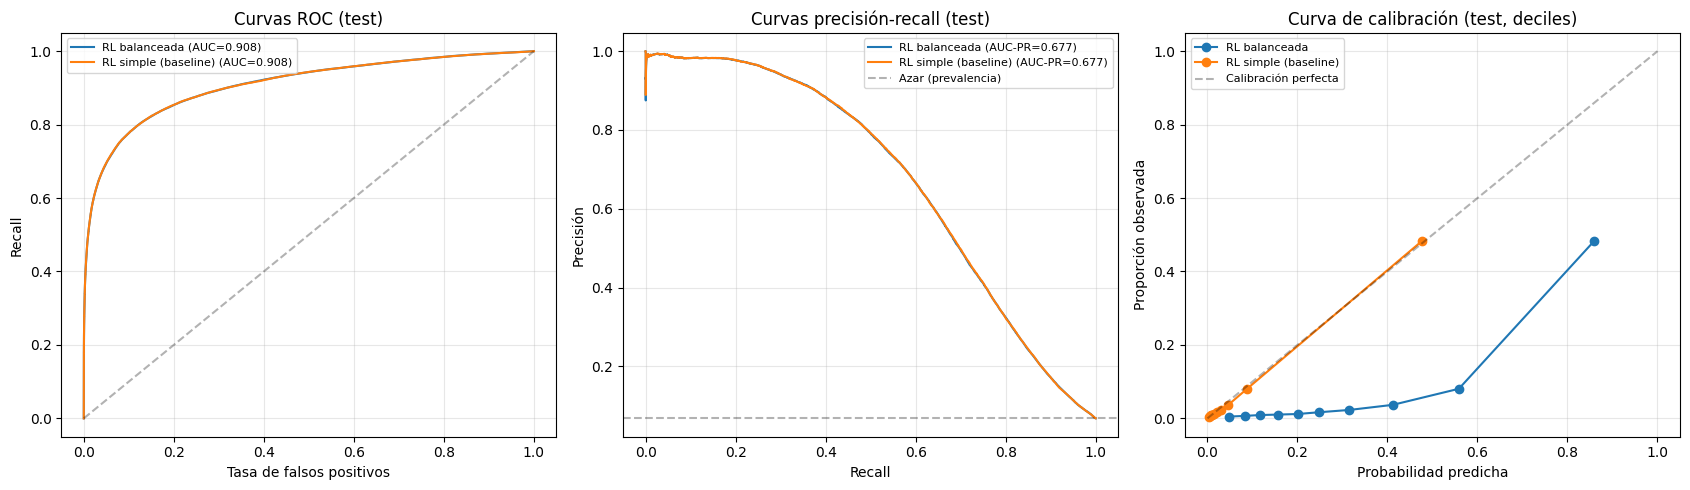

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for k, p in probas_te.items():
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, label=f"{k} (AUC={roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rc, pr, label=f"{k} (AUC-PR={average_precision_score(y_te, p):.3f})")
    frac, media = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[2].plot(media, frac, "o-", label=k)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.3)
axes[0].set(title="Curvas ROC (test)", xlabel="Tasa de falsos positivos", ylabel="Recall")
axes[1].axhline(y_te.mean(), color="k", ls="--", alpha=.3, label="Azar (prevalencia)")
axes[1].set(title="Curvas precisión-recall (test)", xlabel="Recall", ylabel="Precisión")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.3, label="Calibración perfecta")
axes[2].set(title="Curva de calibración (test, deciles)", xlabel="Probabilidad predicha", ylabel="Proporción observada")
for a in axes:
    a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Interpretación

Las cifras corresponden a la ejecución en Colab (scikit-learn 1.6.1); los valores exactos están en las tablas de arriba.

**1. La curva de regularización tiene la forma esperada.** Con `C ≥ 0.01` el modelo ya no cambia (AUC-PR en validación 0.663 con L1 y con L2): con 3.2 millones de registros y 53 columnas, una regularización débil no tiene nada que corregir. Al regularizar más, L2 con `C = 0.0001` mejora levemente (0.666), y con `C = 0.00001` empeora (0.661): ahí el modelo encoge demasiado los coeficientes y empieza a **subajustar**. En todos los casos el AUC-PR de train y de validación es casi igual, así que no hay sobreajuste; la caída con C muy chico es subajuste (también baja en train).

**2. L1 confirma que muchas categorías aportan poco.** Con `C = 0.001`, L1 deja en cero 14 de las 53 columnas y mantiene prácticamente el mismo AUC-PR (0.664). Con `C = 0.0001` elimina 43 columnas y baja a 0.661, y con `C = 0.00001` deja una sola columna activa y cae a 0.592.

**3. Modelo elegido: L2 con `C = 0.0001`.** Es la única combinación dentro de la tolerancia de 0.001 del mejor AUC-PR en validación. Todos los ajustes convergieron con `saga` (entre 11 y 68 iteraciones, lejos del límite de 1000).

**4. En test, el balanceo no mejora la discriminación.** La regresión balanceada y el baseline tienen el mismo AUC-ROC (0.908) y prácticamente el mismo AUC-PR (0.677 frente a 0.677); sus curvas ROC y precisión-recall se superponen. La pequeña ganancia que la regularización mostraba en validación no se traduce en una ventaja sobre el baseline.

**5. Lo que cambia es el punto de operación con el umbral 0.5.** La regresión balanceada detecta 39 548 de 48 907 casos (recall 0.81, frente a 0.47 del baseline), pero genera 87 893 falsas alarmas, unas 2.2 por cada caso real, y su precisión baja de 0.82 a 0.31. El F1 cae de 0.60 a 0.45. En la práctica, balancear equivale a usar el baseline con un umbral más bajo: el modelo ordena igual, pero marca muchos más casos. Elegir entre ambos depende de cuánto cuesta perder un caso frente a dar una falsa alarma.

**6. Las probabilidades quedan infladas.** En el decil de mayor riesgo el modelo predice en promedio cerca de 0.86, pero la proporción observada de bajo peso es cercana a 0.48, y en los demás deciles la sobreestimación es aún mayor en términos relativos. Es consecuencia directa de `class_weight="balanced"`, que entrena como si la mitad de los casos fueran de bajo peso. Para usarlas como riesgo absoluto habría que recalibrarlas; el baseline ya está bien calibrado.

**7. Comparación con Almeida et al. (2026).** El patrón es el del paper: balancear sube el recall y baja la precisión, con el AUC-ROC prácticamente igual. Almeida reporta para la regresión balanceada recall 0.688, F1 0.567 y AUC-ROC 0.85; aquí el recall es mayor (0.81), el F1 menor (0.45) y el AUC-ROC mayor (0.91). No son directamente comparables: su prevalencia es mayor (9.5% frente a 6.8%), usan otras variables y la edad gestacional en tres categorías, mientras que aquí entra en semanas.

## 6. Limitaciones

- **`DUR_EMB_PARTO` se conoce al momento del parto, no antes.** El encuadre es "información registrada al momento del parto, antes del pesaje"; no es una predicción prenatal.
- **Umbral fijo en 0.5**, como en los papers. Precisión, recall y F1 dependen de esa elección; AUC-ROC y AUC-PR no.
- **La prevalencia del test (6.81%) es mayor que la de train (6.32%).** Precisión y F1 en test no son directamente comparables con validación.
- **El peso tiene redondeo en 2500 g** (16 353 registros exactos), lo que mete ruido en la etiqueta justo en el umbral.
- **El test no incluye diciembre de 2025.**
- **El CNV no registra variables clínicas** (controles prenatales, anemia, hipertensión, IMC), que podrían mejorar la predicción.
- El balanceo infla las probabilidades: la curva de calibración lo muestra. Si se quisieran usar como riesgo absoluto habría que recalibrarlas.
- No se exploró elastic-net intermedio (0 < `l1_ratio` < 1) por su costo de cómputo. La partición de validación es única.